In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from woody_filter import woody


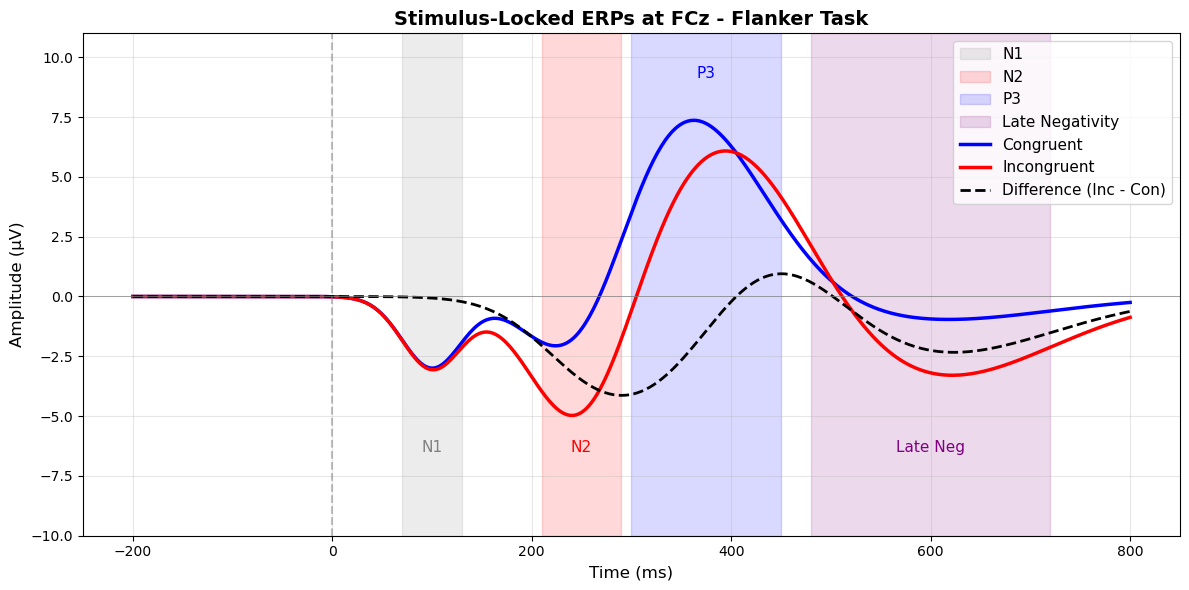

In [2]:
# Parameters
sfreq = 500  # Hz
tmin, tmax = -0.2, 0.8  # locked to stimulus onset
n_times = int((tmax - tmin) * sfreq) + 1
times = np.linspace(tmin, tmax, n_times)

# N1 (early visual, similar for both conditions)
n1_time = 0.10  # 100ms
n1_amplitude = -3  # µV
n1_width = 0.03

# N2 (conflict-related, LARGER for incongruent)
n2_time = 0.25  # 250ms
n2_amplitude_congruent = -5  # µV (smaller)
n2_amplitude_incongruent = -6  # µV (larger - more conflict)
n2_width = 0.05 # 50ms

# P3 (decision/evaluation, timing may differ)
p3_time_congruent = 0.35  # 350ms
p3_time_incongruent = 0.40  # 400ms (delayed by conflict)
p3_amplitude_congruent = 8  # µV
p3_amplitude_incongruent = 7  # µV (slightly reduced)
p3_width = 0.08  # 80ms (broader)

# Late Negativity (sustained monitoring/conflict resolution)
ln_time = 0.60  # 600ms
ln_amplitude_congruent = -1  # µV (minimal)
ln_amplitude_incongruent = -3.5  # µV (larger - sustained conflict processing)
ln_width = 0.12  # 120ms (broad, sustained)

# Generate CONGRUENT ERP
n1_cong = n1_amplitude * np.exp(-0.5 * ((times - n1_time) / n1_width) ** 2)
n2_cong = n2_amplitude_congruent * np.exp(-0.5 * ((times - n2_time) / n2_width) ** 2)
p3_cong = p3_amplitude_congruent * np.exp(-0.5 * ((times - p3_time_congruent) / p3_width) ** 2)
ln_cong = ln_amplitude_congruent * np.exp(-0.5 * ((times - ln_time) / ln_width) ** 2)
erp_congruent = n1_cong + n2_cong + p3_cong + ln_cong

# Generate INCONGRUENT ERP
n1_incong = n1_amplitude * np.exp(-0.5 * ((times - n1_time) / n1_width) ** 2)
n2_incong = n2_amplitude_incongruent * np.exp(-0.5 * ((times - n2_time) / n2_width) ** 2)
p3_incong = p3_amplitude_incongruent * np.exp(-0.5 * ((times - p3_time_incongruent) / p3_width) ** 2)
ln_incong = ln_amplitude_incongruent * np.exp(-0.5 * ((times - ln_time) / ln_width) ** 2)
erp_incongruent = n1_incong + n2_incong + p3_incong + ln_incong

# Difference wave (conflict effect)
erp_difference = erp_incongruent - erp_congruent

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

# Add light colored boxes for each ERP component
ax.axvspan(70, 130, alpha=0.15, color='gray', label='N1')
ax.axvspan(210, 290, alpha=0.15, color='red', label='N2')
ax.axvspan(300, 450, alpha=0.15, color='blue', label='P3')
ax.axvspan(480, 720, alpha=0.15, color='purple', label='Late Negativity')

# Plot ERPs
ax.plot(times * 1000, erp_congruent, 'b', linewidth=2.5, label='Congruent')
ax.plot(times * 1000, erp_incongruent, 'r', linewidth=2.5, label='Incongruent')
ax.plot(times * 1000, erp_difference, 'k--', linewidth=2, label='Difference (Inc - Con)')

ax.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax.axhline(0, color='gray', linestyle='-', linewidth=0.5)

# Add text labels INSIDE visible range
ax.text(100, -6, 'N1', ha='center', va='top', fontsize=11, color='gray')
ax.text(250, -6, 'N2', ha='center', va='top', fontsize=11, color='red')
ax.text(375, 9, 'P3', ha='center', va='bottom', fontsize=11, color='blue')
ax.text(600, -6, 'Late Neg', ha='center', va='top', fontsize=11, color='purple')

ax.set_xlabel('Time (ms)', fontsize=12)
ax.set_ylabel('Amplitude (µV)', fontsize=12)
ax.set_title('Stimulus-Locked ERPs at FCz - Flanker Task', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')
ax.grid(alpha=0.3)
ax.set_ylim(-10, 11)

plt.tight_layout()
plt.show()

/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_82966/3038588983.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


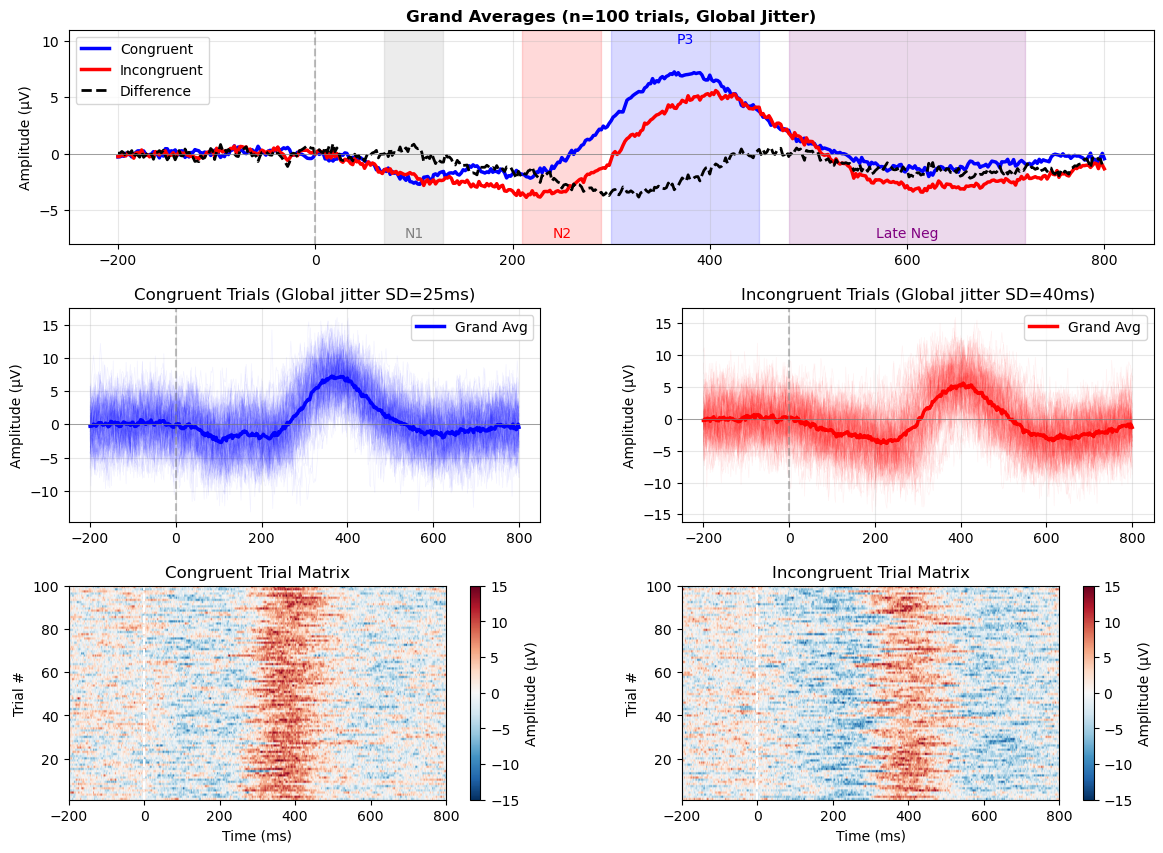

In [3]:
# GLOBAL JITTER PARAMETERS (in seconds)
jitter_sd_congruent = 0.025  # 25ms SD for congruent trials
jitter_sd_incongruent = 0.040  # 40ms SD for incongruent trials (more RT variability)

def generate_pink_noise(n_samples):
    """Generate pink (1/f) noise"""
    white = np.random.randn(n_samples)
    fft_white = np.fft.rfft(white)
    freqs = np.fft.rfftfreq(n_samples)
    freqs[0] = 1  # Avoid division by zero
    pink_fft = fft_white / np.sqrt(freqs)
    pink = np.fft.irfft(pink_fft, n=n_samples)
    pink = pink / np.std(pink)
    return pink

# Noise and trial parameters
n_trials = 100
noise_amplitude = 3  # microvolts (pink noise SD)

# Generate CONGRUENT trials WITH GLOBAL JITTER
trials_congruent = np.zeros((n_trials, n_times))
jitters_congruent = []

for trial in range(n_trials):
    global_jitter = np.random.normal(0, jitter_sd_congruent)
    jitters_congruent.append(global_jitter)
    
    n1 = n1_amplitude * np.exp(-0.5 * ((times - (n1_time + global_jitter)) / n1_width) ** 2)
    n2 = n2_amplitude_congruent * np.exp(-0.5 * ((times - (n2_time + global_jitter)) / n2_width) ** 2)
    p3 = p3_amplitude_congruent * np.exp(-0.5 * ((times - (p3_time_congruent + global_jitter)) / p3_width) ** 2)
    ln = ln_amplitude_congruent * np.exp(-0.5 * ((times - (ln_time + global_jitter)) / ln_width) ** 2)
    
    noise = generate_pink_noise(n_times) * noise_amplitude
    trials_congruent[trial, :] = n1 + n2 + p3 + ln + noise

# Generate INCONGRUENT trials WITH GLOBAL JITTER
trials_incongruent = np.zeros((n_trials, n_times))
jitters_incongruent = []

for trial in range(n_trials):
    global_jitter = np.random.normal(0, jitter_sd_incongruent)
    jitters_incongruent.append(global_jitter)
    
    n1 = n1_amplitude * np.exp(-0.5 * ((times - (n1_time + global_jitter)) / n1_width) ** 2)
    n2 = n2_amplitude_incongruent * np.exp(-0.5 * ((times - (n2_time + global_jitter)) / n2_width) ** 2)
    p3 = p3_amplitude_incongruent * np.exp(-0.5 * ((times - (p3_time_incongruent + global_jitter)) / p3_width) ** 2)
    ln = ln_amplitude_incongruent * np.exp(-0.5 * ((times - (ln_time + global_jitter)) / ln_width) ** 2)
    
    noise = generate_pink_noise(n_times) * noise_amplitude
    trials_incongruent[trial, :] = n1 + n2 + p3 + ln + noise

jitters_congruent = np.array(jitters_congruent)
jitters_incongruent = np.array(jitters_incongruent)

# Compute grand averages
grand_avg_congruent = trials_congruent.mean(axis=0)
grand_avg_incongruent = trials_incongruent.mean(axis=0)
grand_avg_difference = grand_avg_incongruent - grand_avg_congruent

# Plot
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# Grand averages
ax1 = fig.add_subplot(gs[0, :])

# Add light colored boxes
ax1.axvspan(70, 130, alpha=0.15, color='gray')
ax1.axvspan(210, 290, alpha=0.15, color='red')
ax1.axvspan(300, 450, alpha=0.15, color='blue')
ax1.axvspan(480, 720, alpha=0.15, color='purple')

ax1.plot(times * 1000, grand_avg_congruent, 'b', linewidth=2.5, label='Congruent')
ax1.plot(times * 1000, grand_avg_incongruent, 'r', linewidth=2.5, label='Incongruent')
ax1.plot(times * 1000, grand_avg_difference, 'k--', linewidth=2, label='Difference')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)

# Add labels INSIDE the plot
ax1.text(100, -6.5, 'N1', ha='center', va='top', fontsize=10, color='gray')
ax1.text(250, -6.5, 'N2', ha='center', va='top', fontsize=10, color='red')
ax1.text(375, 9.5, 'P3', ha='center', va='bottom', fontsize=10, color='blue')
ax1.text(600, -6.5, 'Late Neg', ha='center', va='top', fontsize=10, color='purple')

ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Grand Averages (n={n_trials} trials, Global Jitter)', fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_ylim(-8, 11)

# Congruent single trials
ax2 = fig.add_subplot(gs[1, 0])
ax2.plot(times * 1000, trials_congruent.T, 'b', alpha=0.05, linewidth=0.5)
ax2.plot(times * 1000, grand_avg_congruent, 'b', linewidth=2.5, label='Grand Avg')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_ylabel('Amplitude (µV)')
ax2.set_title(f'Congruent Trials (Global jitter SD={jitter_sd_congruent*1000:.0f}ms)')
ax2.legend()
ax2.grid(alpha=0.3)

# Incongruent single trials
ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(times * 1000, trials_incongruent.T, 'r', alpha=0.05, linewidth=0.5)
ax3.plot(times * 1000, grand_avg_incongruent, 'r', linewidth=2.5, label='Grand Avg')
ax3.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax3.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax3.set_ylabel('Amplitude (µV)')
ax3.set_title(f'Incongruent Trials (Global jitter SD={jitter_sd_incongruent*1000:.0f}ms)')
ax3.legend()
ax3.grid(alpha=0.3)

# Trial-by-trial heatmaps
ax4 = fig.add_subplot(gs[2, 0])
im4 = ax4.imshow(trials_congruent, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                 cmap='RdBu_r', vmin=-15, vmax=15)
ax4.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax4.set_xlabel('Time (ms)')
ax4.set_ylabel('Trial #')
ax4.set_title('Congruent Trial Matrix')
plt.colorbar(im4, ax=ax4, label='Amplitude (µV)')

ax5 = fig.add_subplot(gs[2, 1])
im5 = ax5.imshow(trials_incongruent, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                 cmap='RdBu_r', vmin=-15, vmax=15)
ax5.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax5.set_xlabel('Time (ms)')
ax5.set_ylabel('Trial #')
ax5.set_title('Incongruent Trial Matrix')
plt.colorbar(im5, ax=ax5, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_82966/407448130.py:141: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


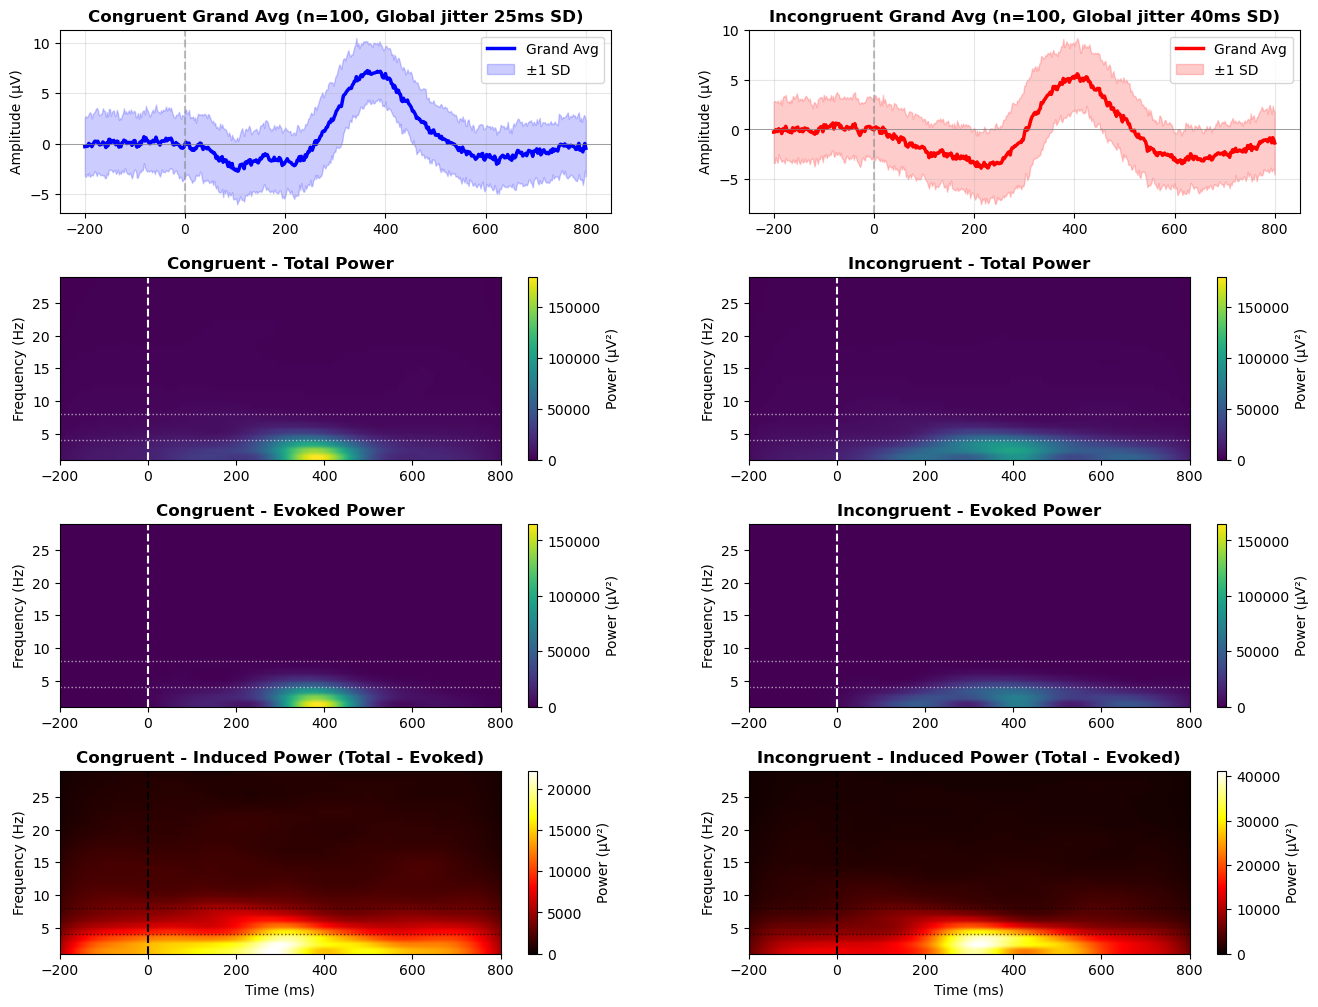

In [4]:
# Time-Frequency parameters
freqs = np.arange(1, 30, 1)  # 1-30 Hz
n_cycles = freqs / 2.0

def compute_tfr_trial(signal, freqs, n_cycles, sfreq):
    """Compute TFR for a single trial"""
    tfr = np.zeros((len(freqs), len(signal)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * \
                  np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(signal, wavelet, mode='same')
        tfr[idx, :] = np.abs(convolved) ** 2
    return tfr

# CONGRUENT: Evoked, Total, Induced
tfr_evoked_cong = compute_tfr_trial(grand_avg_congruent, freqs, n_cycles, sfreq)

tfr_total_cong = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    tfr_total_cong += compute_tfr_trial(trials_congruent[trial, :], freqs, n_cycles, sfreq)
tfr_total_cong /= n_trials

tfr_induced_cong = tfr_total_cong - tfr_evoked_cong

# INCONGRUENT: Evoked, Total, Induced
tfr_evoked_incong = compute_tfr_trial(grand_avg_incongruent, freqs, n_cycles, sfreq)

tfr_total_incong = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    tfr_total_incong += compute_tfr_trial(trials_incongruent[trial, :], freqs, n_cycles, sfreq)
tfr_total_incong /= n_trials

tfr_induced_incong = tfr_total_incong - tfr_evoked_incong

# Compute SDs for grand averages
sd_cong = trials_congruent.std(axis=0)
sd_incong = trials_incongruent.std(axis=0)

# Plot
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(4, 2, hspace=0.35, wspace=0.25)

# Row 1: Grand averages
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(times * 1000, grand_avg_congruent, 'b', linewidth=2.5, label='Grand Avg')
ax1.fill_between(times * 1000, grand_avg_congruent - sd_cong, grand_avg_congruent + sd_cong,
                  color='b', alpha=0.2, label='±1 SD')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Congruent Grand Avg (n={n_trials}, Global jitter {jitter_sd_congruent*1000:.0f}ms SD)', fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(times * 1000, grand_avg_incongruent, 'r', linewidth=2.5, label='Grand Avg')
ax2.fill_between(times * 1000, grand_avg_incongruent - sd_incong, grand_avg_incongruent + sd_incong,
                  color='r', alpha=0.2, label='±1 SD')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_ylabel('Amplitude (µV)')
ax2.set_title(f'Incongruent Grand Avg (n={n_trials}, Global jitter {jitter_sd_incongruent*1000:.0f}ms SD)', fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Row 2: Total Power
vmax_total = max(tfr_total_cong.max(), tfr_total_incong.max())
ax3 = fig.add_subplot(gs[1, 0])
im3 = ax3.imshow(tfr_total_cong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_total)
ax3.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax3.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax3.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax3.set_ylabel('Frequency (Hz)')
ax3.set_title('Congruent - Total Power', fontweight='bold')
plt.colorbar(im3, ax=ax3, label='Power (µV²)')

ax4 = fig.add_subplot(gs[1, 1])
im4 = ax4.imshow(tfr_total_incong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_total)
ax4.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax4.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax4.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax4.set_ylabel('Frequency (Hz)')
ax4.set_title('Incongruent - Total Power', fontweight='bold')
plt.colorbar(im4, ax=ax4, label='Power (µV²)')

# Row 3: Evoked Power
vmax_evoked = max(tfr_evoked_cong.max(), tfr_evoked_incong.max())
ax5 = fig.add_subplot(gs[2, 0])
im5 = ax5.imshow(tfr_evoked_cong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_evoked)
ax5.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax5.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax5.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax5.set_ylabel('Frequency (Hz)')
ax5.set_title('Congruent - Evoked Power', fontweight='bold')
plt.colorbar(im5, ax=ax5, label='Power (µV²)')

ax6 = fig.add_subplot(gs[2, 1])
im6 = ax6.imshow(tfr_evoked_incong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_evoked)
ax6.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax6.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax6.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax6.set_ylabel('Frequency (Hz)')
ax6.set_title('Incongruent - Evoked Power', fontweight='bold')
plt.colorbar(im6, ax=ax6, label='Power (µV²)')

# Row 4: Induced Power - SEPARATE SCALES
ax7 = fig.add_subplot(gs[3, 0])
im7 = ax7.imshow(tfr_induced_cong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=tfr_induced_cong.max(), cmap='hot')
ax7.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax7.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax7.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax7.set_xlabel('Time (ms)')
ax7.set_ylabel('Frequency (Hz)')
ax7.set_title('Congruent - Induced Power (Total - Evoked)', fontweight='bold')
plt.colorbar(im7, ax=ax7, label='Power (µV²)')

ax8 = fig.add_subplot(gs[3, 1])
im8 = ax8.imshow(tfr_induced_incong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=tfr_induced_incong.max(), cmap='hot')
ax8.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax8.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax8.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax8.set_xlabel('Time (ms)')
ax8.set_ylabel('Frequency (Hz)')
ax8.set_title('Incongruent - Induced Power (Total - Evoked)', fontweight='bold')
plt.colorbar(im8, ax=ax8, label='Power (µV²)')

plt.tight_layout()
plt.show()

/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_82966/1330161660.py:112: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


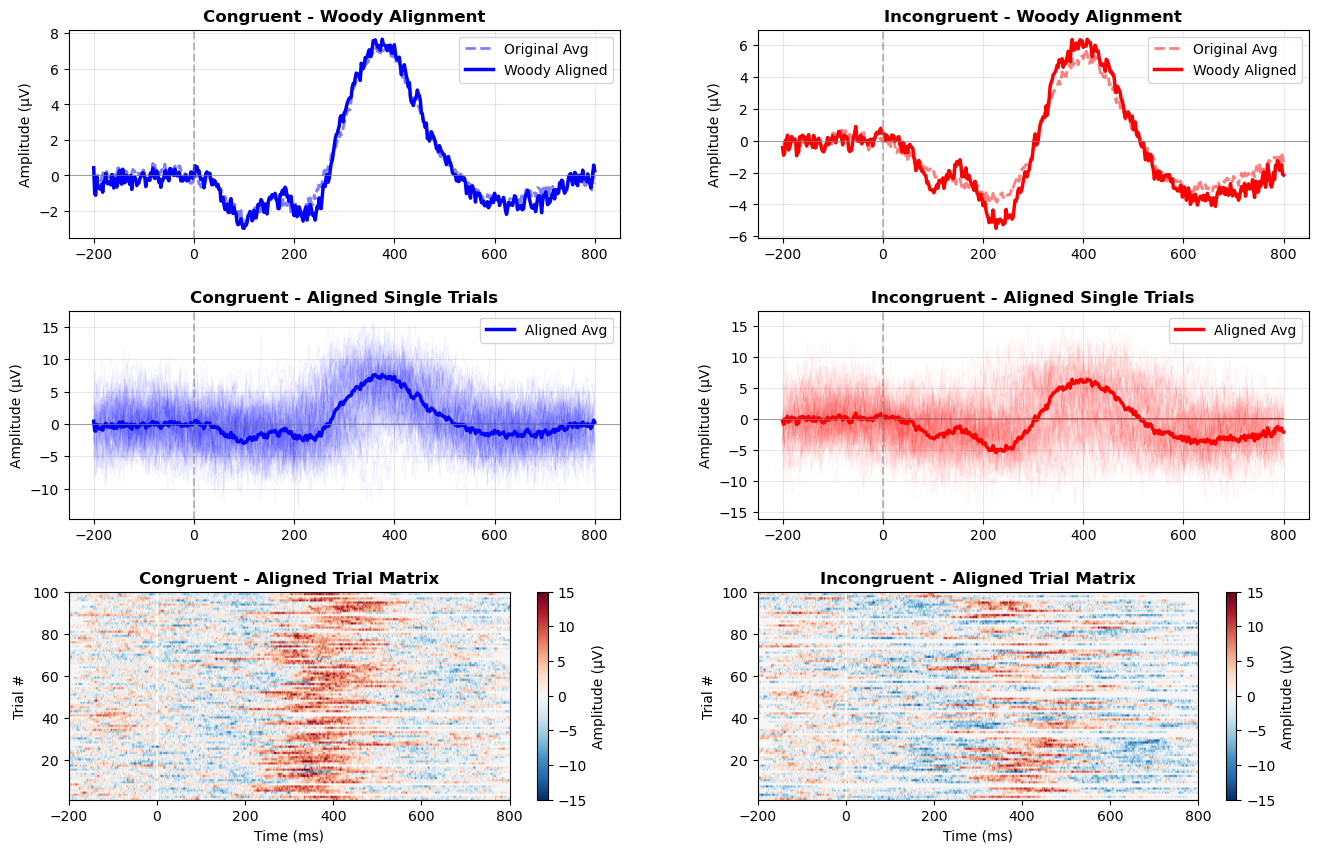

In [5]:
# Apply Woody filter to CONGRUENT trials
trials_cong_transposed = trials_congruent.T  # Shape: (n_timepoints, n_trials)

aligned_avg_cong, detected_lags_cong = woody(
    trials_cong_transposed,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased'
)

# Reconstruct individual aligned congruent trials
aligned_trials_cong = np.zeros_like(trials_congruent)
for i in range(n_trials):
    lag = detected_lags_cong[i]
    if lag > 0:
        aligned_trials_cong[i, lag:] = trials_congruent[i, :-lag]
    elif lag < 0:
        aligned_trials_cong[i, :lag] = trials_congruent[i, -lag:]
    else:
        aligned_trials_cong[i, :] = trials_congruent[i, :]

# Apply Woody filter to INCONGRUENT trials
trials_incong_transposed = trials_incongruent.T

aligned_avg_incong, detected_lags_incong = woody(
    trials_incong_transposed,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased'
)

# Reconstruct individual aligned incongruent trials
aligned_trials_incong = np.zeros_like(trials_incongruent)
for i in range(n_trials):
    lag = detected_lags_incong[i]
    if lag > 0:
        aligned_trials_incong[i, lag:] = trials_incongruent[i, :-lag]
    elif lag < 0:
        aligned_trials_incong[i, :lag] = trials_incongruent[i, -lag:]
    else:
        aligned_trials_incong[i, :] = trials_incongruent[i, :]

# Plot
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 2, hspace=0.35, wspace=0.25)

# Row 1: Aligned grand averages comparison
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(times * 1000, grand_avg_congruent, 'b--', linewidth=2, alpha=0.5, label='Original Avg')
ax1.plot(times * 1000, aligned_avg_cong, 'b', linewidth=2.5, label='Woody Aligned')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title('Congruent - Woody Alignment', fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(times * 1000, grand_avg_incongruent, 'r--', linewidth=2, alpha=0.5, label='Original Avg')
ax2.plot(times * 1000, aligned_avg_incong, 'r', linewidth=2.5, label='Woody Aligned')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_ylabel('Amplitude (µV)')
ax2.set_title('Incongruent - Woody Alignment', fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Row 2: Aligned single trials
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(times * 1000, aligned_trials_cong.T, 'b', alpha=0.05, linewidth=0.5)
ax3.plot(times * 1000, aligned_avg_cong, 'b', linewidth=2.5, label='Aligned Avg')
ax3.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax3.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax3.set_ylabel('Amplitude (µV)')
ax3.set_title('Congruent - Aligned Single Trials', fontweight='bold')
ax3.legend()
ax3.grid(alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(times * 1000, aligned_trials_incong.T, 'r', alpha=0.05, linewidth=0.5)
ax4.plot(times * 1000, aligned_avg_incong, 'r', linewidth=2.5, label='Aligned Avg')
ax4.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax4.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax4.set_ylabel('Amplitude (µV)')
ax4.set_title('Incongruent - Aligned Single Trials', fontweight='bold')
ax4.legend()
ax4.grid(alpha=0.3)

# Row 3: Trial matrices
ax5 = fig.add_subplot(gs[2, 0])
im5 = ax5.imshow(aligned_trials_cong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                 cmap='RdBu_r', vmin=-15, vmax=15)
ax5.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax5.set_xlabel('Time (ms)')
ax5.set_ylabel('Trial #')
ax5.set_title('Congruent - Aligned Trial Matrix', fontweight='bold')
plt.colorbar(im5, ax=ax5, label='Amplitude (µV)')

ax6 = fig.add_subplot(gs[2, 1])
im6 = ax6.imshow(aligned_trials_incong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, 1, n_trials],
                 cmap='RdBu_r', vmin=-15, vmax=15)
ax6.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax6.set_xlabel('Time (ms)')
ax6.set_ylabel('Trial #')
ax6.set_title('Incongruent - Aligned Trial Matrix', fontweight='bold')
plt.colorbar(im6, ax=ax6, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

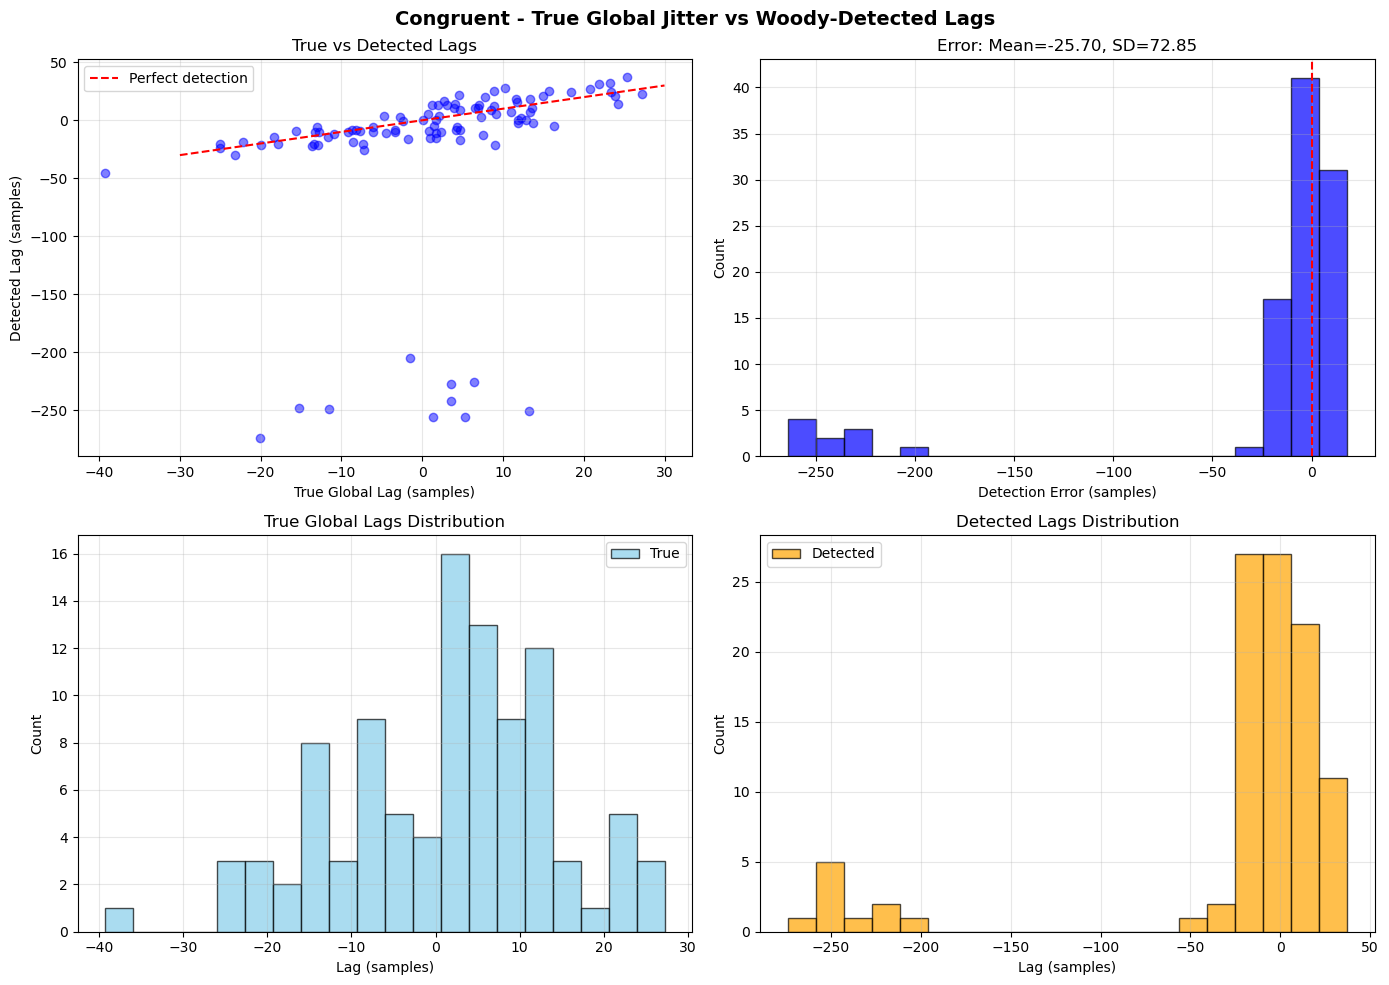

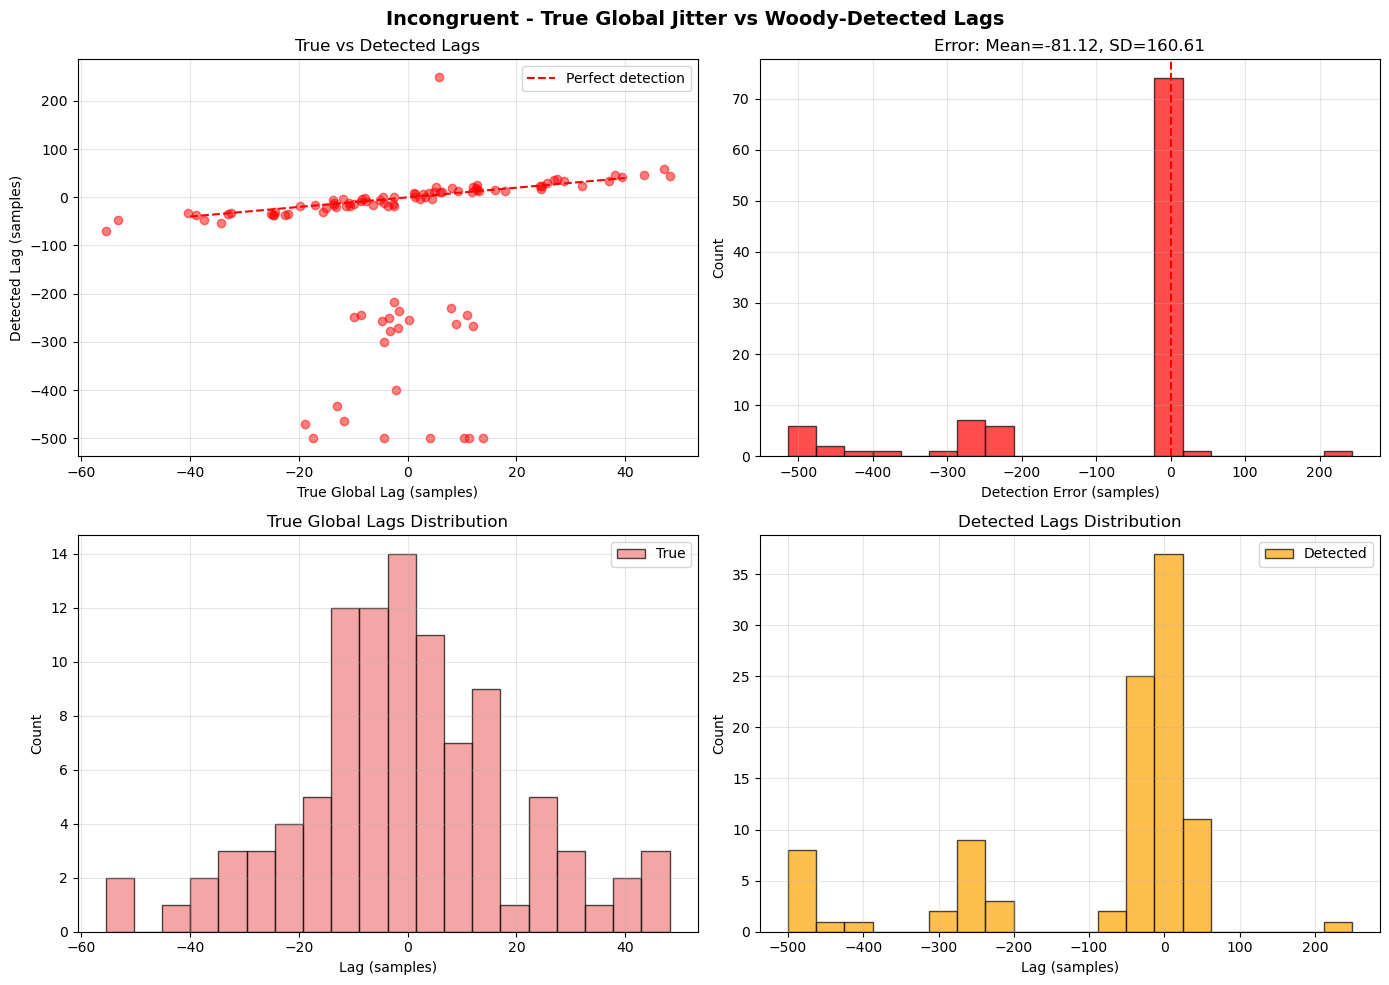

In [6]:
# Apply Woody filter to both conditions (using existing global jitter trials)
trials_cong_transposed = trials_congruent.T
aligned_avg_cong, detected_lags_cong = woody(trials_cong_transposed, tol=0.1, max_it=100, 
                                              est_mthd='woody', xcorr_mthd='unbiased')

trials_incong_transposed = trials_incongruent.T
aligned_avg_incong, detected_lags_incong = woody(trials_incong_transposed, tol=0.1, max_it=100,
                                                  est_mthd='woody', xcorr_mthd='unbiased')

# Convert true global jitters to samples
true_lags_cong_samples = jitters_congruent * sfreq
true_lags_incong_samples = jitters_incongruent * sfreq

# Compare for CONGRUENT
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Congruent - True Global Jitter vs Woody-Detected Lags', fontsize=14, fontweight='bold')

axes[0, 0].scatter(true_lags_cong_samples, detected_lags_cong, alpha=0.5, color='blue')
axes[0, 0].plot([-30, 30], [-30, 30], 'r--', label='Perfect detection')
axes[0, 0].set_xlabel('True Global Lag (samples)')
axes[0, 0].set_ylabel('Detected Lag (samples)')
axes[0, 0].set_title('True vs Detected Lags')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

error_cong = detected_lags_cong - true_lags_cong_samples
axes[0, 1].hist(error_cong, bins=20, edgecolor='black', color='blue', alpha=0.7)
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Detection Error (samples)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title(f'Error: Mean={error_cong.mean():.2f}, SD={error_cong.std():.2f}')
axes[0, 1].grid(alpha=0.3)

axes[1, 0].hist(true_lags_cong_samples, bins=20, edgecolor='black', alpha=0.7, label='True', color='skyblue')
axes[1, 0].set_xlabel('Lag (samples)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('True Global Lags Distribution')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].hist(detected_lags_cong, bins=20, edgecolor='black', alpha=0.7, label='Detected', color='orange')
axes[1, 1].set_xlabel('Lag (samples)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Detected Lags Distribution')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Compare for INCONGRUENT
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Incongruent - True Global Jitter vs Woody-Detected Lags', fontsize=14, fontweight='bold')

axes[0, 0].scatter(true_lags_incong_samples, detected_lags_incong, alpha=0.5, color='red')
axes[0, 0].plot([-40, 40], [-40, 40], 'r--', label='Perfect detection')
axes[0, 0].set_xlabel('True Global Lag (samples)')
axes[0, 0].set_ylabel('Detected Lag (samples)')
axes[0, 0].set_title('True vs Detected Lags')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

error_incong = detected_lags_incong - true_lags_incong_samples
axes[0, 1].hist(error_incong, bins=20, edgecolor='black', color='red', alpha=0.7)
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Detection Error (samples)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title(f'Error: Mean={error_incong.mean():.2f}, SD={error_incong.std():.2f}')
axes[0, 1].grid(alpha=0.3)

axes[1, 0].hist(true_lags_incong_samples, bins=20, edgecolor='black', alpha=0.7, label='True', color='lightcoral')
axes[1, 0].set_xlabel('Lag (samples)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('True Global Lags Distribution')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].hist(detected_lags_incong, bins=20, edgecolor='black', alpha=0.7, label='Detected', color='orange')
axes[1, 1].set_xlabel('Lag (samples)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Detected Lags Distribution')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_82966/4010830175.py:128: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


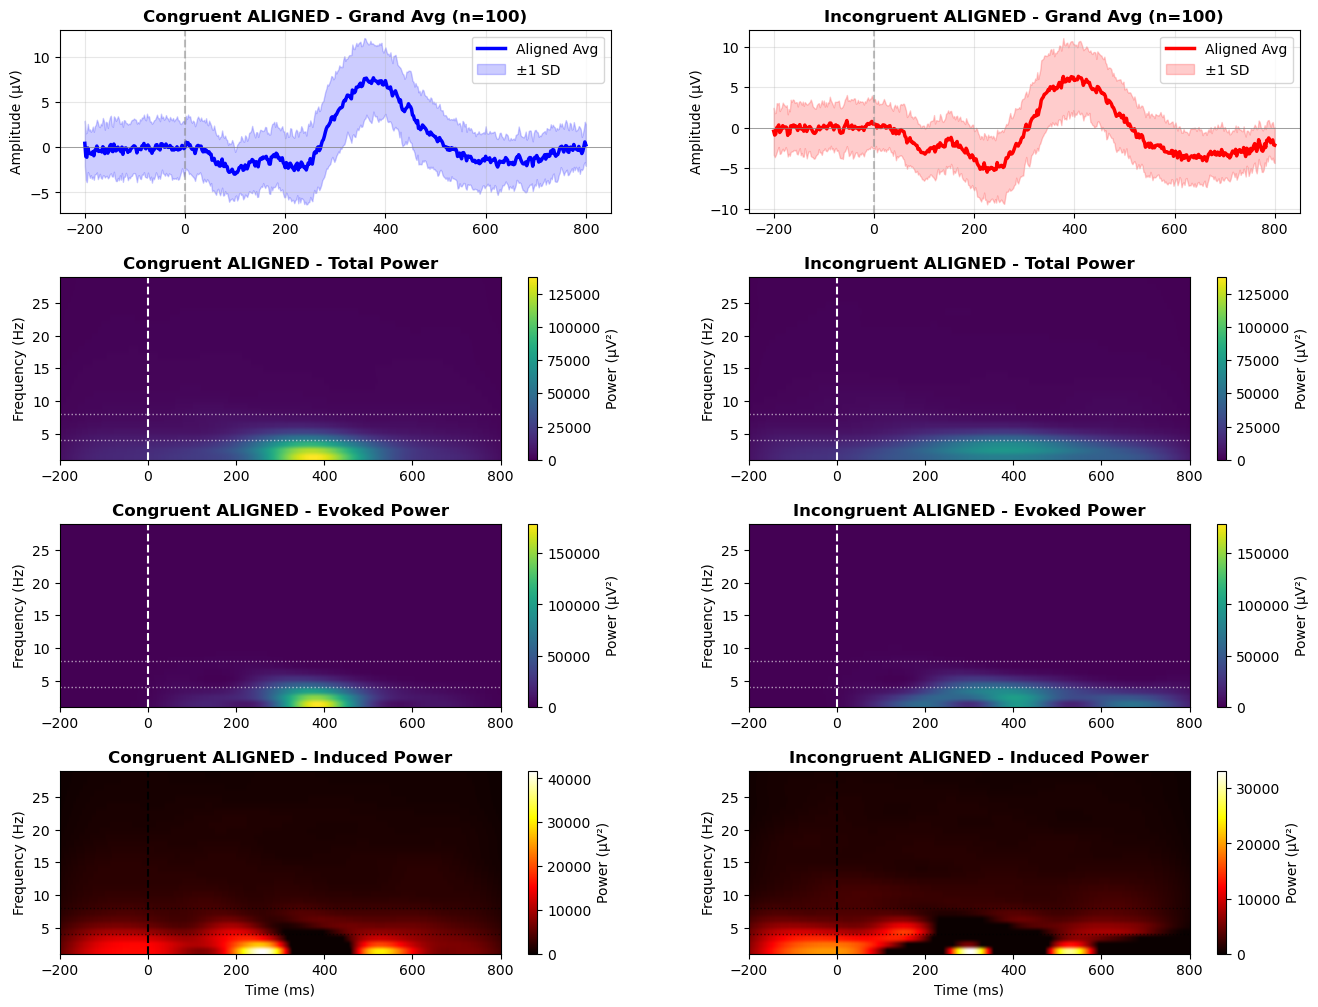

In [9]:
sd_aligned_cong = aligned_trials_cong.std(axis=0)
sd_aligned_incong = aligned_trials_incong.std(axis=0)

# Time-Frequency Analysis on ALIGNED data (1-30 Hz)
freqs = np.arange(1, 30, 1)
n_cycles = freqs / 2.0

# CONGRUENT ALIGNED: Evoked, Total, Induced
tfr_evoked_aligned_cong = compute_tfr_trial(aligned_avg_cong, freqs, n_cycles, sfreq)

tfr_total_aligned_cong = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    tfr_total_aligned_cong += compute_tfr_trial(aligned_trials_cong[trial, :], freqs, n_cycles, sfreq)
tfr_total_aligned_cong /= n_trials

tfr_induced_aligned_cong = tfr_total_aligned_cong - tfr_evoked_aligned_cong

# INCONGRUENT ALIGNED: Evoked, Total, Induced
tfr_evoked_aligned_incong = compute_tfr_trial(aligned_avg_incong, freqs, n_cycles, sfreq)

tfr_total_aligned_incong = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    tfr_total_aligned_incong += compute_tfr_trial(aligned_trials_incong[trial, :], freqs, n_cycles, sfreq)
tfr_total_aligned_incong /= n_trials

tfr_induced_aligned_incong = tfr_total_aligned_incong - tfr_evoked_aligned_incong

# Plot
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(4, 2, hspace=0.35, wspace=0.25)

# Row 1: Grand averages ALIGNED
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(times * 1000, aligned_avg_cong, 'b', linewidth=2.5, label='Aligned Avg')
ax1.fill_between(times * 1000, aligned_avg_cong - sd_aligned_cong, 
                 aligned_avg_cong + sd_aligned_cong, color='b', alpha=0.2, label='±1 SD')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Congruent ALIGNED - Grand Avg (n={n_trials})', fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(times * 1000, aligned_avg_incong, 'r', linewidth=2.5, label='Aligned Avg')
ax2.fill_between(times * 1000, aligned_avg_incong - sd_aligned_incong,
                 aligned_avg_incong + sd_aligned_incong, color='r', alpha=0.2, label='±1 SD')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_ylabel('Amplitude (µV)')
ax2.set_title(f'Incongruent ALIGNED - Grand Avg (n={n_trials})', fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Row 2: Total Power ALIGNED
vmax_total_aligned = max(tfr_total_aligned_cong.max(), tfr_total_aligned_incong.max())
ax3 = fig.add_subplot(gs[1, 0])
im3 = ax3.imshow(tfr_total_aligned_cong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_total_aligned)
ax3.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax3.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax3.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax3.set_ylabel('Frequency (Hz)')
ax3.set_title('Congruent ALIGNED - Total Power', fontweight='bold')
plt.colorbar(im3, ax=ax3, label='Power (µV²)')

ax4 = fig.add_subplot(gs[1, 1])
im4 = ax4.imshow(tfr_total_aligned_incong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_total_aligned)
ax4.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax4.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax4.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax4.set_ylabel('Frequency (Hz)')
ax4.set_title('Incongruent ALIGNED - Total Power', fontweight='bold')
plt.colorbar(im4, ax=ax4, label='Power (µV²)')

# Row 3: Evoked Power ALIGNED
vmax_evoked_aligned = max(tfr_evoked_aligned_cong.max(), tfr_evoked_aligned_incong.max())
ax5 = fig.add_subplot(gs[2, 0])
im5 = ax5.imshow(tfr_evoked_aligned_cong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_evoked_aligned)
ax5.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax5.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax5.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax5.set_ylabel('Frequency (Hz)')
ax5.set_title('Congruent ALIGNED - Evoked Power', fontweight='bold')
plt.colorbar(im5, ax=ax5, label='Power (µV²)')

ax6 = fig.add_subplot(gs[2, 1])
im6 = ax6.imshow(tfr_evoked_aligned_incong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_evoked_aligned)
ax6.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax6.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax6.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax6.set_ylabel('Frequency (Hz)')
ax6.set_title('Incongruent ALIGNED - Evoked Power', fontweight='bold')
plt.colorbar(im6, ax=ax6, label='Power (µV²)')

# Row 4: Induced Power ALIGNED - SEPARATE SCALES
ax7 = fig.add_subplot(gs[3, 0])
im7 = ax7.imshow(tfr_induced_aligned_cong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=tfr_induced_aligned_cong.max(), cmap='hot')
ax7.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax7.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax7.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax7.set_xlabel('Time (ms)')
ax7.set_ylabel('Frequency (Hz)')
ax7.set_title('Congruent ALIGNED - Induced Power', fontweight='bold')
plt.colorbar(im7, ax=ax7, label='Power (µV²)')

ax8 = fig.add_subplot(gs[3, 1])
im8 = ax8.imshow(tfr_induced_aligned_incong, aspect='auto', origin='lower',
                 extent=[tmin * 1000, tmax * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=tfr_induced_aligned_incong.max(), cmap='hot')
ax8.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax8.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax8.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax8.set_xlabel('Time (ms)')
ax8.set_ylabel('Frequency (Hz)')
ax8.set_title('Incongruent ALIGNED - Induced Power', fontweight='bold')
plt.colorbar(im8, ax=ax8, label='Power (µV²)')

plt.tight_layout()
plt.show()

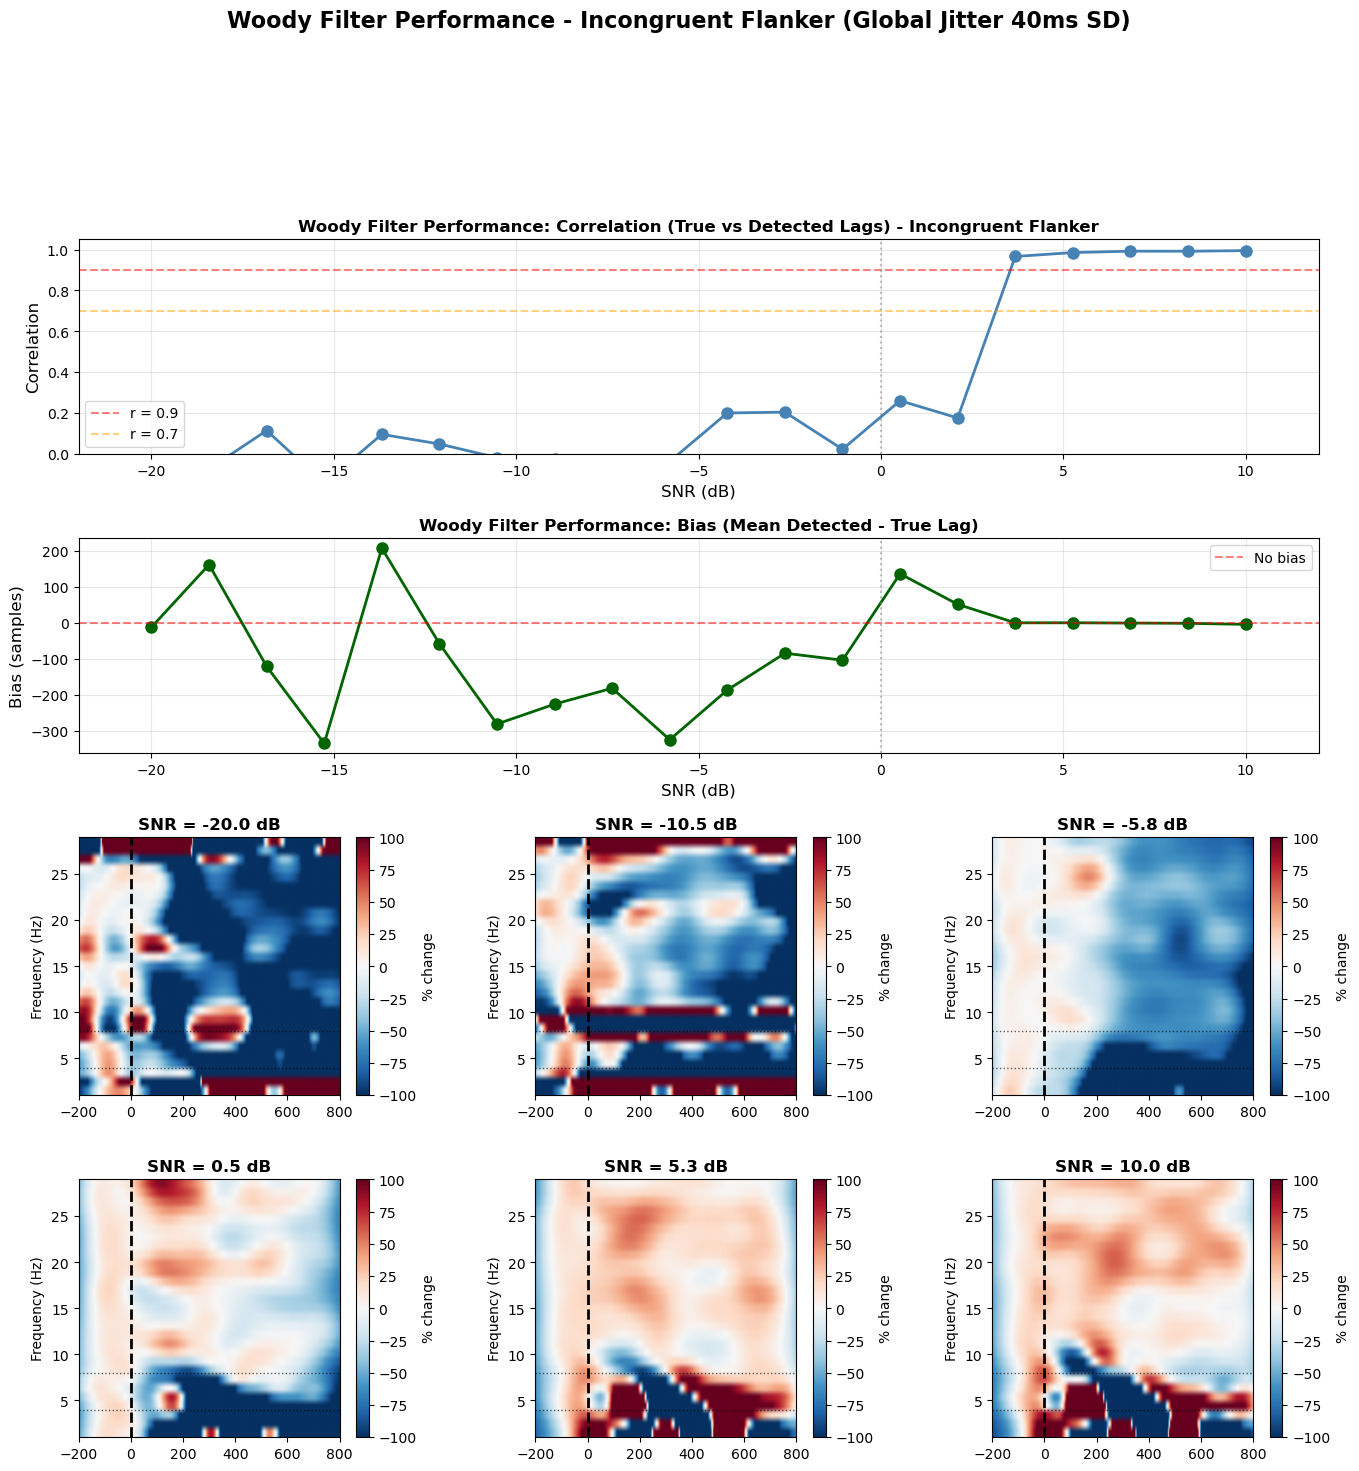

In [10]:
def generate_pink_noise(n_samples):
    """Generate pink (1/f) noise"""
    white = np.random.randn(n_samples)
    fft_white = np.fft.rfft(white)
    freqs = np.fft.rfftfreq(n_samples)
    freqs[0] = 1
    pink_fft = fft_white / np.sqrt(freqs)
    pink = np.fft.irfft(pink_fft, n=n_samples)
    pink = pink / np.std(pink)
    return pink

# Compute signal RMS for INCONGRUENT condition (using our established parameters)
signal_rms = np.sqrt(np.mean(erp_incongruent**2))

# Target SNR values
target_snr_db = np.linspace(-20, 10, 20)
snr_values = []
correlations = []
biases = []
n_trials_snr = 100
jitter_sd = jitter_sd_incongruent  # 40ms SD for incongruent

# Store trials for later TFR plotting
stored_trials = {}

# Compute correlations and biases for all SNR levels
for snr_db in target_snr_db:
    snr_linear = 10**(snr_db / 20)
    noise_amp = signal_rms / snr_linear
    
    trials_signal = np.zeros((n_trials_snr, n_times))
    trials_noisy = np.zeros((n_trials_snr, n_times))
    true_jitters = np.zeros(n_trials_snr)
    
    for trial in range(n_trials_snr):
        # Global jitter
        global_jitter = np.random.normal(0, jitter_sd)
        true_jitters[trial] = global_jitter
        
        # Generate all components with same jitter
        n1 = n1_amplitude * np.exp(-0.5 * ((times - (n1_time + global_jitter)) / n1_width) ** 2)
        n2 = n2_amplitude_incongruent * np.exp(-0.5 * ((times - (n2_time + global_jitter)) / n2_width) ** 2)
        p3 = p3_amplitude_incongruent * np.exp(-0.5 * ((times - (p3_time_incongruent + global_jitter)) / p3_width) ** 2)
        ln = ln_amplitude_incongruent * np.exp(-0.5 * ((times - (ln_time + global_jitter)) / ln_width) ** 2)
        
        signal_trial = n1 + n2 + p3 + ln
        noise = generate_pink_noise(n_times) * noise_amp
        
        trials_signal[trial, :] = signal_trial
        trials_noisy[trial, :] = signal_trial + noise
    
    snr_values.append(snr_db)
    stored_trials[snr_db] = trials_noisy.copy()
    
    # Apply Woody filter
    trials_T = trials_noisy.T
    aligned_avg, detected_lags = woody(trials_T, tol=0.1, max_it=100,
                                       est_mthd='woody', xcorr_mthd='unbiased')
    
    true_lags_samples = true_jitters * sfreq
    corr = np.corrcoef(true_lags_samples, detected_lags)[0, 1]
    correlations.append(corr)
    
    bias = (detected_lags - true_lags_samples).mean()
    biases.append(bias)

# Create combined figure
fig = plt.figure(figsize=(16, 20))
gs = fig.add_gridspec(5, 3, hspace=0.35, wspace=0.4, height_ratios=[1, 1, 1.2, 1.2, 1.2])

# Row 1: Correlation plot
ax_corr = fig.add_subplot(gs[0, :])
ax_corr.plot(snr_values, correlations, 'o-', linewidth=2, markersize=8, color='steelblue')
ax_corr.axhline(0.9, color='r', linestyle='--', alpha=0.5, label='r = 0.9')
ax_corr.axhline(0.7, color='orange', linestyle='--', alpha=0.5, label='r = 0.7')
ax_corr.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax_corr.set_xlabel('SNR (dB)', fontsize=12)
ax_corr.set_ylabel('Correlation', fontsize=12)
ax_corr.set_title('Woody Filter Performance: Correlation (True vs Detected Lags) - Incongruent Flanker', fontweight='bold')
ax_corr.grid(alpha=0.3)
ax_corr.legend()
ax_corr.set_ylim(0, 1.05)
ax_corr.set_xlim(-22, 12)

# Row 2: Bias plot
ax_bias = fig.add_subplot(gs[1, :])
ax_bias.plot(snr_values, biases, 'o-', linewidth=2, markersize=8, color='darkgreen')
ax_bias.axhline(0, color='r', linestyle='--', alpha=0.5, label='No bias')
ax_bias.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax_bias.set_xlabel('SNR (dB)', fontsize=12)
ax_bias.set_ylabel('Bias (samples)', fontsize=12)
ax_bias.set_title('Woody Filter Performance: Bias (Mean Detected - True Lag)', fontweight='bold')
ax_bias.grid(alpha=0.3)
ax_bias.legend()
ax_bias.set_xlim(-22, 12)

# Rows 3-5: Baseline-corrected TFR at different SNR levels
snr_levels_to_plot = [-20, -10, -5, 0, 5, 10]
freqs_tfr = np.arange(1, 30, 1)
n_cycles_tfr = freqs_tfr / 2.0

baseline_window = (times >= -0.2) & (times < 0)

for idx, target_snr in enumerate(snr_levels_to_plot):
    row = 2 + idx // 3
    col = idx % 3
    ax = fig.add_subplot(gs[row, col])
    
    snr_array = np.array(snr_values)
    closest_idx = np.argmin(np.abs(snr_array - target_snr))
    snr_db = snr_values[closest_idx]
    
    trials_noisy = stored_trials[snr_db]
    trials_T = trials_noisy.T
    
    aligned_avg, detected_lags = woody(trials_T, tol=0.1, max_it=100,
                                       est_mthd='woody', xcorr_mthd='unbiased')
    
    # Reconstruct aligned trials
    aligned_trials = np.zeros_like(trials_noisy)
    for i in range(n_trials_snr):
        lag = detected_lags[i]
        if lag > 0:
            aligned_trials[i, lag:] = trials_noisy[i, :-lag]
        elif lag < 0:
            aligned_trials[i, :lag] = trials_noisy[i, -lag:]
        else:
            aligned_trials[i, :] = trials_noisy[i, :]
    
    # Compute TFRs
    tfr_evoked_aligned = compute_tfr_trial(aligned_avg, freqs_tfr, n_cycles_tfr, sfreq)
    
    tfr_total_aligned = np.zeros((len(freqs_tfr), len(times)))
    for trial in range(n_trials_snr):
        tfr_total_aligned += compute_tfr_trial(aligned_trials[trial, :], freqs_tfr, n_cycles_tfr, sfreq)
    tfr_total_aligned /= n_trials_snr
    
    tfr_induced_aligned = tfr_total_aligned - tfr_evoked_aligned
    
    # Baseline correction (percent change)
    baseline_mean = tfr_induced_aligned[:, baseline_window].mean(axis=1, keepdims=True)
    tfr_induced_baseline = (tfr_induced_aligned - baseline_mean) / baseline_mean * 100
    
    # Plot
    im = ax.imshow(tfr_induced_baseline, aspect='auto', origin='lower',
                   extent=[tmin * 1000, tmax * 1000, freqs_tfr[0], freqs_tfr[-1]],
                   cmap='RdBu_r', vmin=-100, vmax=100)
    ax.axvline(0, color='black', linestyle='--', linewidth=2)
    ax.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
    ax.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
    ax.set_title(f'SNR = {snr_db:.1f} dB', fontweight='bold')
    ax.set_ylabel('Frequency (Hz)')
    
    if row == 4:
        ax.set_xlabel('Time (ms)')
    
    plt.colorbar(im, ax=ax, label='% change')

plt.suptitle('Woody Filter Performance - Incongruent Flanker (Global Jitter 40ms SD)', fontsize=16, y=0.995, fontweight='bold')
plt.show()

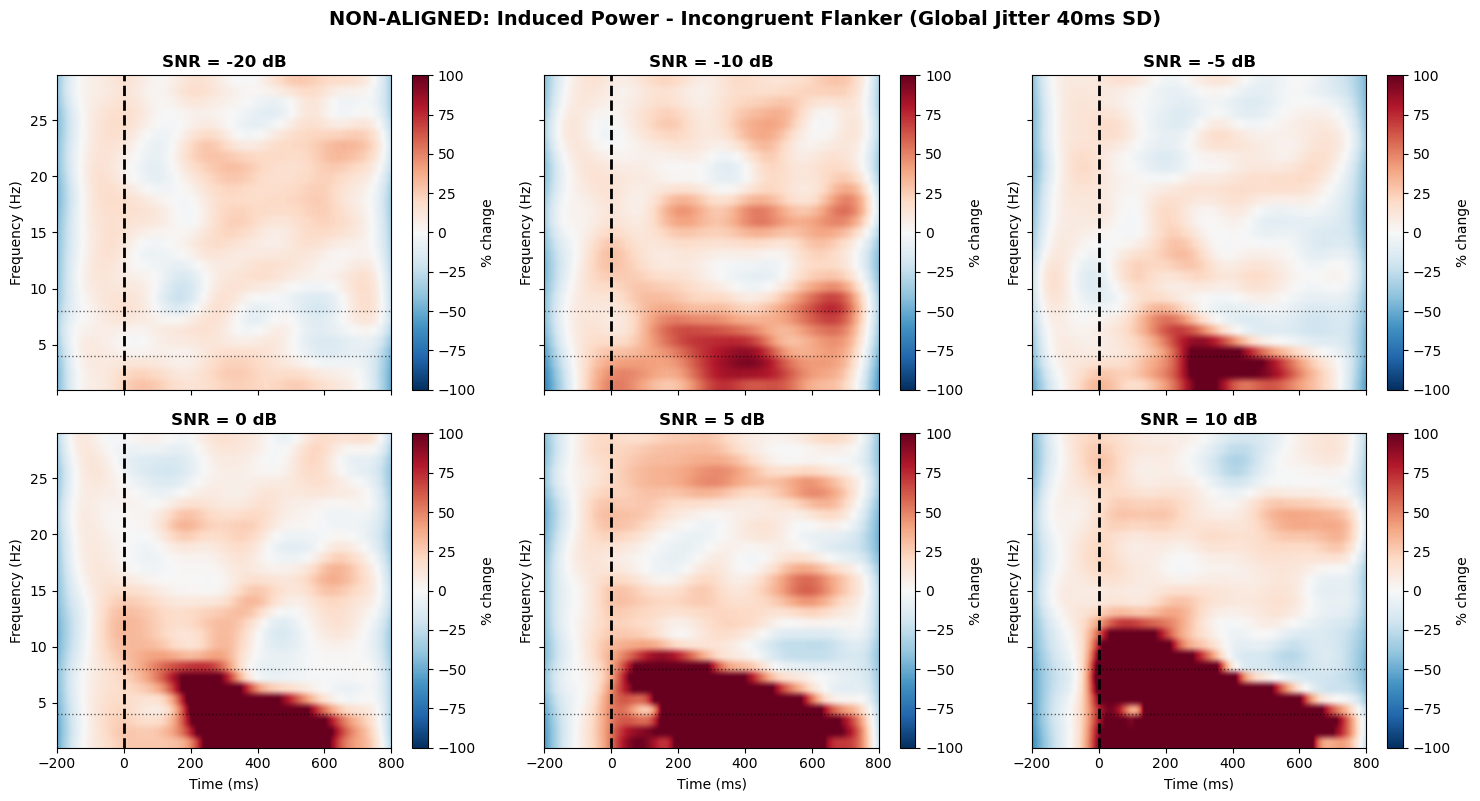

In [11]:
# Compute signal RMS for INCONGRUENT condition
signal_rms = np.sqrt(np.mean(erp_incongruent**2))

# Selected SNR levels to plot
snr_levels_to_plot = [-20, -10, -5, 0, 5, 10]
freqs_tfr = np.arange(1, 30, 1)
n_cycles_tfr = freqs_tfr / 2.0
n_trials_snr = 100
jitter_sd = jitter_sd_incongruent  # 40ms SD

# Baseline window
baseline_window = (times >= -0.2) & (times < 0)

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.flatten()

for idx, snr_db in enumerate(snr_levels_to_plot):
    ax = axes[idx]
    
    # Calculate noise amplitude
    snr_linear = 10**(snr_db / 20)
    noise_amp = signal_rms / snr_linear
    
    # Generate trials WITHOUT alignment
    trials_noisy = np.zeros((n_trials_snr, n_times))
    
    for trial in range(n_trials_snr):
        # Global jitter
        global_jitter = np.random.normal(0, jitter_sd)
        
        # Generate all components with same jitter
        n1 = n1_amplitude * np.exp(-0.5 * ((times - (n1_time + global_jitter)) / n1_width) ** 2)
        n2 = n2_amplitude_incongruent * np.exp(-0.5 * ((times - (n2_time + global_jitter)) / n2_width) ** 2)
        p3 = p3_amplitude_incongruent * np.exp(-0.5 * ((times - (p3_time_incongruent + global_jitter)) / p3_width) ** 2)
        ln = ln_amplitude_incongruent * np.exp(-0.5 * ((times - (ln_time + global_jitter)) / ln_width) ** 2)
        
        noise = generate_pink_noise(n_times) * noise_amp
        trials_noisy[trial, :] = n1 + n2 + p3 + ln + noise
    
    # NO Woody filtering - use raw trials
    grand_avg_raw = trials_noisy.mean(axis=0)
    
    # Compute TFRs
    tfr_evoked_raw = compute_tfr_trial(grand_avg_raw, freqs_tfr, n_cycles_tfr, sfreq)
    
    tfr_total_raw = np.zeros((len(freqs_tfr), len(times)))
    for trial in range(n_trials_snr):
        tfr_total_raw += compute_tfr_trial(trials_noisy[trial, :], freqs_tfr, n_cycles_tfr, sfreq)
    tfr_total_raw /= n_trials_snr
    
    tfr_induced_raw = tfr_total_raw - tfr_evoked_raw
    
    # Baseline correction (percent change)
    baseline_mean = tfr_induced_raw[:, baseline_window].mean(axis=1, keepdims=True)
    tfr_induced_baseline = (tfr_induced_raw - baseline_mean) / baseline_mean * 100
    
    # Plot
    im = ax.imshow(tfr_induced_baseline, aspect='auto', origin='lower',
                   extent=[tmin * 1000, tmax * 1000, freqs_tfr[0], freqs_tfr[-1]],
                   cmap='RdBu_r', vmin=-100, vmax=100)
    ax.axvline(0, color='black', linestyle='--', linewidth=2)
    ax.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
    ax.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
    ax.set_title(f'SNR = {snr_db} dB', fontweight='bold')
    ax.set_ylabel('Frequency (Hz)')
    
    if idx >= 3:
        ax.set_xlabel('Time (ms)')
    
    plt.colorbar(im, ax=ax, label='% change')

plt.suptitle('NON-ALIGNED: Induced Power - Incongruent Flanker (Global Jitter 40ms SD)', fontsize=14, y=0.995, fontweight='bold')
plt.tight_layout()
plt.show()